In [ ]:
# Experiment 8: Multi-Agent Task Allocation and Coordination

import pandas as pd
import matplotlib.pyplot as plt


In [ ]:

# Exercise 1: Define Manager Agent, Delivery Agents, and Tasks

manager = {
    "name": "Manager Agent",
    "role": "Coordinates task allocation"
}

agents = {
    "Agent A": {"cost_rate": 10, "time_rate": 1.0},
    "Agent B": {"cost_rate": 8,  "time_rate": 1.2},
    "Agent C": {"cost_rate": 12, "time_rate": 0.8}
}

tasks = {
    "T1": {"location": "Area 1", "resource": "Van 1",
           "distance": 5, "deadline": 10},
    "T2": {"location": "Area 2", "resource": "Van 2",
           "distance": 8, "deadline": 15},
    "T3": {"location": "Area 1", "resource": "Van 1",
           "distance": 6, "deadline": 12},
    "T4": {"location": "Area 3", "resource": "Van 3",
           "distance": 4, "deadline": 10},
    "T5": {"location": "Area 4", "resource": "Van 2",
           "distance": 7, "deadline": 14},
    "T6": {"location": "Area 5", "resource": "Van 1",
           "distance": 3, "deadline": 8}
}

print(manager)
print("\nDelivery Agents:")
for agent, details in agents.items():
    print(agent, details)

print("\nDelivery Tasks:")
for task, details in tasks.items():
    print(task, details)


{'name': 'Manager Agent', 'role': 'Coordinates task allocation'}

Delivery Agents:
Agent A {'cost_rate': 10, 'time_rate': 1.0}
Agent B {'cost_rate': 8, 'time_rate': 1.2}
Agent C {'cost_rate': 12, 'time_rate': 0.8}

Delivery Tasks:
T1 {'location': 'Area 1', 'resource': 'Van 1', 'distance': 5, 'deadline': 10}
T2 {'location': 'Area 2', 'resource': 'Van 2', 'distance': 8, 'deadline': 15}
T3 {'location': 'Area 1', 'resource': 'Van 1', 'distance': 6, 'deadline': 12}
T4 {'location': 'Area 3', 'resource': 'Van 3', 'distance': 4, 'deadline': 10}
T5 {'location': 'Area 4', 'resource': 'Van 2', 'distance': 7, 'deadline': 14}
T6 {'location': 'Area 5', 'resource': 'Van 1', 'distance': 3, 'deadline': 8}


In [ ]:

# Exercise 2: PGP Coordination

local_plans = {
    "Agent A": [
        {"task": "T1", "location": "Area 1",
         "resource": "Van 1", "start": 9, "end": 10}
    ],
    "Agent B": [
        {"task": "T3", "location": "Area 1",
         "resource": "Van 1", "start": 9, "end": 10}
    ],
    "Agent C": [
        {"task": "T4", "location": "Area 3",
         "resource": "Van 3", "start": 9, "end": 10}
    ]
}

print("Initial Local Plans:")
for agent, plan in local_plans.items():
    print(agent, plan)

# Detect overlapping use of the same resource
conflicts = []

for agent1 in local_plans:
    for agent2 in local_plans:
        if agent1 >= agent2:
            continue

        for p1 in local_plans[agent1]:
            for p2 in local_plans[agent2]:
                same_resource = p1["resource"] == p2["resource"]
                overlapping = (
                    p1["start"] < p2["end"]
                    and p2["start"] < p1["end"]
                )

                if same_resource and overlapping:
                    conflicts.append((agent1, agent2, p1, p2))
                    print(
                        f"\nConflict detected between {agent1} "
                        f"and {agent2}: {p1['resource']} "
                        f"is needed during overlapping time slots."
                    )

# Resolve conflict by rescheduling Agent B
for agent1, agent2, p1, p2 in conflicts:
    p2["start"] = p1["end"]
    p2["end"] = p2["start"] + 1

print("\nLocal Plans After Conflict Resolution:")
for agent, plan in local_plans.items():
    print(agent, plan)


Initial Local Plans:
Agent A [{'task': 'T1', 'location': 'Area 1', 'resource': 'Van 1', 'start': 9, 'end': 10}]
Agent B [{'task': 'T3', 'location': 'Area 1', 'resource': 'Van 1', 'start': 9, 'end': 10}]
Agent C [{'task': 'T4', 'location': 'Area 3', 'resource': 'Van 3', 'start': 9, 'end': 10}]

Conflict detected between Agent A and Agent B: Van 1 is needed during overlapping time slots.

Local Plans After Conflict Resolution:
Agent A [{'task': 'T1', 'location': 'Area 1', 'resource': 'Van 1', 'start': 9, 'end': 10}]
Agent B [{'task': 'T3', 'location': 'Area 1', 'resource': 'Van 1', 'start': 10, 'end': 11}]
Agent C [{'task': 'T4', 'location': 'Area 3', 'resource': 'Van 3', 'start': 9, 'end': 10}]


In [ ]:

# Exercise 3: Contract Net Protocol (CNP)

def calculate_bid(agent_details, task_details):
    cost = agent_details["cost_rate"] * task_details["distance"]
    time = agent_details["time_rate"] * task_details["distance"]

    # An agent bids only if it can meet the deadline.
    if time <= task_details["deadline"]:
        return {"cost": cost, "time": time}
    else:
        return None


def cnp_allocate(tasks, agents, verbose=True):
    allocation = {}

    for task_name, task_details in tasks.items():
        if verbose:
            print(f"\nManager announces task {task_name}")

        bids = {}

        # Bidding phase
        for agent_name, agent_details in agents.items():
            bid = calculate_bid(agent_details, task_details)

            if bid is not None:
                bids[agent_name] = bid
                if verbose:
                    print(
                        f"{agent_name} bids: "
                        f"Cost = {bid['cost']:.2f}, "
                        f"Time = {bid['time']:.2f}"
                    )
            elif verbose:
                print(f"{agent_name} cannot meet the deadline.")

        # Bid comparison and agent selection
        if bids:
            selected_agent = min(
                bids,
                key=lambda agent: (bids[agent]["cost"],
                                   bids[agent]["time"])
            )

            allocation[task_name] = {
                "Agent": selected_agent,
                "Cost": bids[selected_agent]["cost"],
                "Time": bids[selected_agent]["time"]
            }

            if verbose:
                print(f"Manager awards {task_name} to {selected_agent}")
        else:
            allocation[task_name] = {
                "Agent": "Unassigned",
                "Cost": 0,
                "Time": 0
            }

            if verbose:
                print(f"No valid bids for {task_name}")

    return allocation


allocation = cnp_allocate(tasks, agents)



Manager announces task T1
Agent A bids: Cost = 50.00, Time = 5.00
Agent B bids: Cost = 40.00, Time = 6.00
Agent C bids: Cost = 60.00, Time = 4.00
Manager awards T1 to Agent B

Manager announces task T2
Agent A bids: Cost = 80.00, Time = 8.00
Agent B bids: Cost = 64.00, Time = 9.60
Agent C bids: Cost = 96.00, Time = 6.40
Manager awards T2 to Agent B

Manager announces task T3
Agent A bids: Cost = 60.00, Time = 6.00
Agent B bids: Cost = 48.00, Time = 7.20
Agent C bids: Cost = 72.00, Time = 4.80
Manager awards T3 to Agent B

Manager announces task T4
Agent A bids: Cost = 40.00, Time = 4.00
Agent B bids: Cost = 32.00, Time = 4.80
Agent C bids: Cost = 48.00, Time = 3.20
Manager awards T4 to Agent B

Manager announces task T5
Agent A bids: Cost = 70.00, Time = 7.00
Agent B bids: Cost = 56.00, Time = 8.40
Agent C bids: Cost = 84.00, Time = 5.60
Manager awards T5 to Agent B

Manager announces task T6
Agent A bids: Cost = 30.00, Time = 3.00
Agent B bids: Cost = 24.00, Time = 3.60
Agent C bids:

In [ ]:

# Exercise 4: Display Final Task Allocation

def display_allocation(allocation):
    rows = []

    for task_name, details in allocation.items():
        rows.append({
            "Task": task_name,
            "Selected Agent": details["Agent"],
            "Cost": details["Cost"],
            "Time": details["Time"]
        })

    result_df = pd.DataFrame(rows)

    print("Final Task Allocation:")
    display(result_df)

    total_cost = sum(item["Cost"] for item in allocation.values())
    total_time = sum(item["Time"] for item in allocation.values())

    print(f"\nTotal Cost: {total_cost:.2f}")
    print(f"Total Delivery Time (sum of task times): {total_time:.2f}")

    return result_df


original_df = display_allocation(allocation)


Final Task Allocation:


,Task,Selected Agent,Cost,Time
0,T1,Agent B,40,6.0
1,T2,Agent B,64,9.6
2,T3,Agent B,48,7.2
3,T4,Agent B,32,4.8
4,T5,Agent B,56,8.4
5,T6,Agent B,24,3.6



Total Cost: 264.00
Total Delivery Time (sum of task times): 39.60


In [ ]:

# Exercise 5: Modify Agent Costs and Run CNP Again

# Save the original configuration
original_agents = {
    name: details.copy()
    for name, details in agents.items()
}

# Modify the input costs
modified_agents = {
    name: details.copy()
    for name, details in agents.items()
}

modified_agents["Agent A"]["cost_rate"] = 15
modified_agents["Agent C"]["cost_rate"] = 6

print("Original Agent Cost Rates:")
for name, details in original_agents.items():
    print(f"{name}: {details['cost_rate']}")

print("\nModified Agent Cost Rates:")
for name, details in modified_agents.items():
    print(f"{name}: {details['cost_rate']}")

# Run the allocation again with modified costs
modified_allocation = cnp_allocate(
    tasks, modified_agents, verbose=False
)

print("\nAllocation After Cost Modification:")
modified_df = display_allocation(modified_allocation)


Original Agent Cost Rates:
Agent A: 10
Agent B: 8
Agent C: 12

Modified Agent Cost Rates:
Agent A: 15
Agent B: 8
Agent C: 6

Allocation After Cost Modification:
Final Task Allocation:


,Task,Selected Agent,Cost,Time
0,T1,Agent C,30,4.0
1,T2,Agent C,48,6.4
2,T3,Agent C,36,4.8
3,T4,Agent C,24,3.2
4,T5,Agent C,42,5.6
5,T6,Agent C,18,2.4



Total Cost: 198.00
Total Delivery Time (sum of task times): 26.40


In [ ]:

# Compare agent-wise total assigned cost and time

def agent_summary(allocation, agent_names):
    summary = {}

    for agent in agent_names:
        assigned = [
            details for details in allocation.values()
            if details["Agent"] == agent
        ]

        summary[agent] = {
            "Total Cost": sum(item["Cost"] for item in assigned),
            "Total Time": sum(item["Time"] for item in assigned),
            "Tasks Assigned": len(assigned)
        }

    return summary


original_summary = agent_summary(allocation, original_agents)
modified_summary = agent_summary(modified_allocation, modified_agents)

comparison_rows = []

for agent in agents:
    comparison_rows.append({
        "Agent": agent,
        "Original Cost": original_summary[agent]["Total Cost"],
        "Modified Cost": modified_summary[agent]["Total Cost"],
        "Original Time": original_summary[agent]["Total Time"],
        "Modified Time": modified_summary[agent]["Total Time"],
        "Original Tasks": original_summary[agent]["Tasks Assigned"],
        "Modified Tasks": modified_summary[agent]["Tasks Assigned"]
    })

comparison_df = pd.DataFrame(comparison_rows)

print("Original vs Modified Allocation:")
display(comparison_df.round(2))


Original vs Modified Allocation:


,Agent,Original Cost,Modified Cost,Original Time,Modified Time,Original Tasks,Modified Tasks
0,Agent A,0,0,0.0,0.0,0,0
1,Agent B,264,0,39.6,0.0,6,0
2,Agent C,0,198,0.0,26.4,0,6


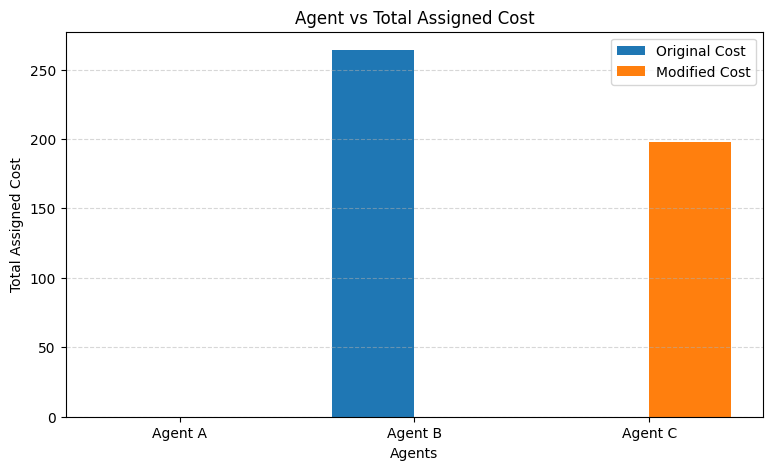

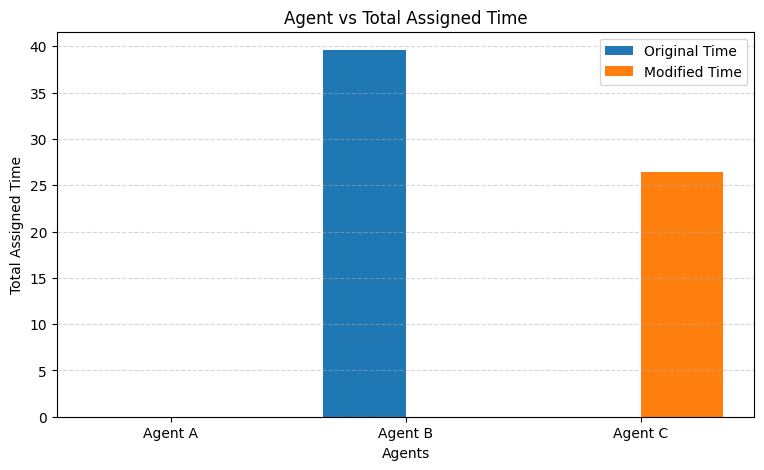

Overall Comparison
Original Total Cost: 264.00
Modified Total Cost: 198.00
Original Total Time: 39.60
Modified Total Time: 26.40


In [ ]:

# Visualization: Compare cost and time before and after modification

agent_names = list(agents.keys())

original_costs = [
    original_summary[a]["Total Cost"] for a in agent_names
]
modified_costs = [
    modified_summary[a]["Total Cost"] for a in agent_names
]

original_times = [
    original_summary[a]["Total Time"] for a in agent_names
]
modified_times = [
    modified_summary[a]["Total Time"] for a in agent_names
]

# Graph 1: Total assigned cost per agent
x = list(range(len(agent_names)))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    [i - width / 2 for i in x],
    original_costs,
    width=width,
    label="Original Cost"
)
plt.bar(
    [i + width / 2 for i in x],
    modified_costs,
    width=width,
    label="Modified Cost"
)

plt.xticks(x, agent_names)
plt.xlabel("Agents")
plt.ylabel("Total Assigned Cost")
plt.title("Agent vs Total Assigned Cost")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


# Graph 2: Total assigned time per agent
plt.figure(figsize=(9, 5))
plt.bar(
    [i - width / 2 for i in x],
    original_times,
    width=width,
    label="Original Time"
)
plt.bar(
    [i + width / 2 for i in x],
    modified_times,
    width=width,
    label="Modified Time"
)

plt.xticks(x, agent_names)
plt.xlabel("Agents")
plt.ylabel("Total Assigned Time")
plt.title("Agent vs Total Assigned Time")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


# Compare overall totals
original_total_cost = sum(original_costs)
modified_total_cost = sum(modified_costs)

original_total_time = sum(original_times)
modified_total_time = sum(modified_times)

print("Overall Comparison")
print(f"Original Total Cost: {original_total_cost:.2f}")
print(f"Modified Total Cost: {modified_total_cost:.2f}")
print(f"Original Total Time: {original_total_time:.2f}")
print(f"Modified Total Time: {modified_total_time:.2f}")
